# SpaceX Falcon 9 Landing Prediction

**Applied Data Science Capstone — Final Project**

This executed notebook asks whether historical mission, payload, launch-site, orbit,
and booster information can help predict whether the Falcon 9 first stage will land
successfully. It combines data collection, wrangling, visualization, SQL, interactive
analytics, and classification.

> Data scope: IBM Skills Network course snapshots ending in November 2020. Results
> describe this historical snapshot, not current SpaceX operations.

In [1]:
from pathlib import Path
import json
import sqlite3

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import HTML, display

ROOT = Path.cwd().resolve().parent
DATA = ROOT / "data"
FIGURES = ROOT / "figures"
SUMMARY = json.loads((ROOT / "analysis_summary.json").read_text())

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
print(f"Project root: {ROOT}")

Project root: /Users/nguyentantai/Documents/Codex/2026-10-02/https-mark-skills-network-learner-1889/work/capstone


## 1. Executive summary

The workflow collects launch data from the public SpaceX API and Wikipedia, cleans
landing outcomes into a binary target, explores operational patterns, builds Folium
maps and a Plotly Dash dashboard, and compares four classifiers. The historical
sample contains **90 launches** from 2010–2020, of which **60 landed successfully**.

In [2]:
summary_table = pd.DataFrame({
    "Metric": ["Launch records", "Successful landings", "Unsuccessful landings", "Overall success rate"],
    "Value": [
        SUMMARY["dataset"]["rows"],
        SUMMARY["dataset"]["successful_landings"],
        SUMMARY["dataset"]["unsuccessful_landings"],
        f'{SUMMARY["dataset"]["overall_success_rate"]:.1f}%'
    ],
})
display(summary_table)

,Metric,Value
0,Launch records,90
1,Successful landings,60
2,Unsuccessful landings,30
3,Overall success rate,66.7%


## 2. Data collection

Two complementary sources are documented in `src/data_collection.py`:

1. **SpaceX REST API** — request past launches, normalize nested JSON, and retain
   launch, payload, rocket, launchpad, and core identifiers.
2. **Wikipedia web scraping** — parse Falcon 9 launch tables with `pandas.read_html`,
   combine matching tables, and export a flat CSV.

The analysis below uses IBM's frozen course files so every result is reproducible.

In [3]:
raw = pd.read_csv(DATA / "dataset_part_1.csv")
clean = pd.read_csv(DATA / "dataset_part_2.csv")
features = pd.read_csv(DATA / "dataset_part_3.csv")
sql_data = pd.read_csv(DATA / "Spacex.csv")
dash_data = pd.read_csv(DATA / "spacex_launch_dash.csv")
geo_data = pd.read_csv(DATA / "spacex_launch_geo.csv")

pd.DataFrame({
    "Dataset": ["API-derived raw", "Wrangled", "Encoded features", "SQL", "Dash", "Folium"],
    "Rows": [len(raw), len(clean), len(features), len(sql_data), len(dash_data), len(geo_data)],
    "Columns": [raw.shape[1], clean.shape[1], features.shape[1], sql_data.shape[1], dash_data.shape[1], geo_data.shape[1]],
})

,Dataset,Rows,Columns
0,API-derived raw,90,17
1,Wrangled,90,18
2,Encoded features,90,83
3,SQL,101,10
4,Dash,56,7
5,Folium,56,13


## 3. Data wrangling

Wrangling standardizes dates and numeric payload mass, imputes missing payload mass
with the sample mean, translates landing outcomes into `Class` (1 = success,
0 = unsuccessful), and one-hot encodes launch site, orbit, serial, and grid-fin / leg /
reuse flags for modeling. The checked feature matrix has no missing values.

In [4]:
clean["Date"] = pd.to_datetime(clean["Date"])
clean["Year"] = clean["Date"].dt.year
clean["Outcome"] = clean["Class"].map({1: "Successful landing", 0: "Unsuccessful landing"})

wrangling_checks = pd.DataFrame({
    "Check": ["Rows", "Duplicate rows", "Missing values in model features", "Positive target share"],
    "Result": [len(clean), clean.duplicated().sum(), int(features.isna().sum().sum()), f'{clean["Class"].mean():.1%}'],
})
display(wrangling_checks)
display(clean[["FlightNumber", "Date", "BoosterVersion", "PayloadMass", "LaunchSite", "Orbit", "Outcome"]].head())

,Check,Result
0,Rows,90
1,Duplicate rows,0
2,Missing values in model features,0
3,Positive target share,66.7%


,FlightNumber,Date,BoosterVersion,PayloadMass,LaunchSite,Orbit,Outcome
0,1,2010-06-04,Falcon 9,6104.959412,CCAFS SLC 40,LEO,Unsuccessful landing
1,2,2012-05-22,Falcon 9,525.000000,CCAFS SLC 40,LEO,Unsuccessful landing
2,3,2013-03-01,Falcon 9,677.000000,CCAFS SLC 40,ISS,Unsuccessful landing
3,4,2013-09-29,Falcon 9,500.000000,VAFB SLC 4E,PO,Unsuccessful landing
4,5,2013-12-03,Falcon 9,3170.000000,CCAFS SLC 40,GTO,Unsuccessful landing


## 4. Exploratory data analysis with visualizations

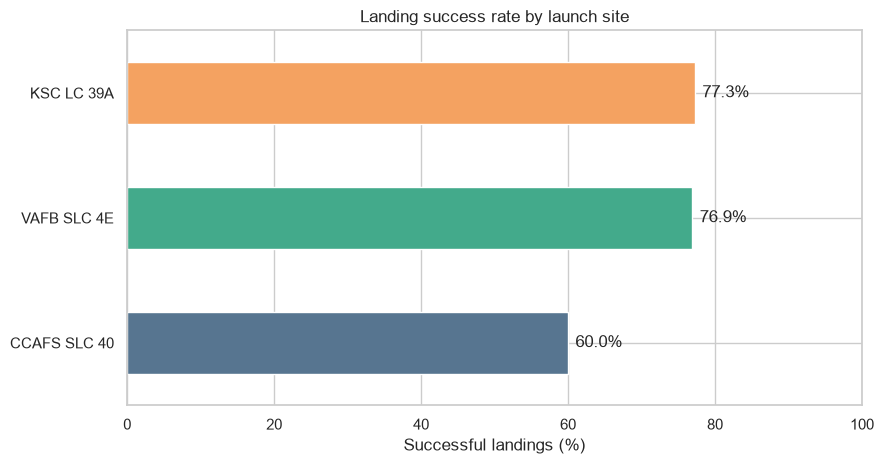

,launches,success_rate
LaunchSite,,
CCAFS SLC 40,55,60.0
VAFB SLC 4E,13,76.9
KSC LC 39A,22,77.3


In [5]:
site = clean.groupby("LaunchSite").agg(launches=("Class", "size"), success_rate=("Class", "mean")).sort_values("success_rate")
ax = (site["success_rate"] * 100).plot(kind="barh", figsize=(9, 4.8), color=["#577590", "#43AA8B", "#F4A261"])
ax.set(title="Landing success rate by launch site", xlabel="Successful landings (%)", ylabel="")
ax.set_xlim(0, 100)
for i, value in enumerate(site["success_rate"] * 100):
    ax.text(value + 1, i, f"{value:.1f}%", va="center")
plt.tight_layout()
plt.show()
display(site.assign(success_rate=lambda d: (d.success_rate * 100).round(1)))

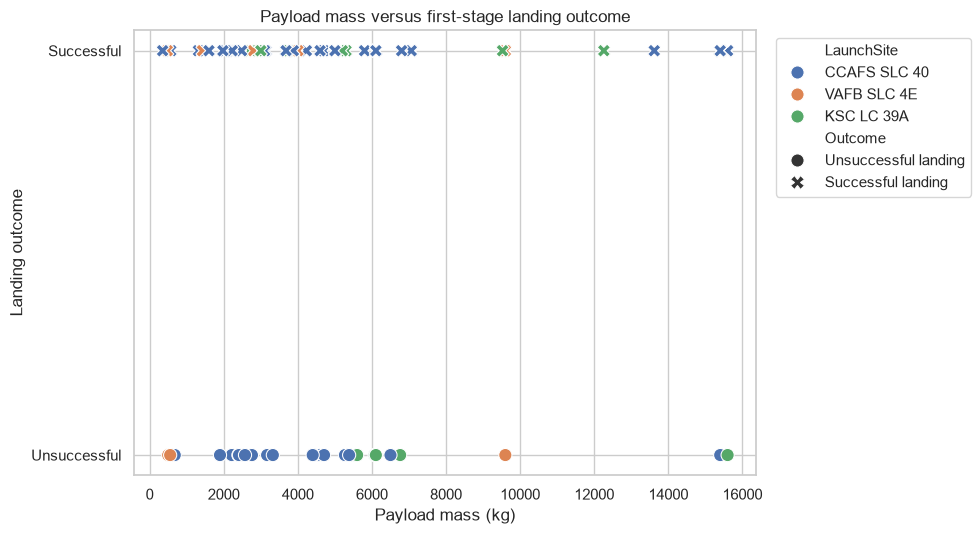

In [6]:
plt.figure(figsize=(10, 5.5))
sns.scatterplot(data=clean, x="PayloadMass", y="Class", hue="LaunchSite", style="Outcome", s=90)
plt.yticks([0, 1], ["Unsuccessful", "Successful"])
plt.title("Payload mass versus first-stage landing outcome")
plt.xlabel("Payload mass (kg)")
plt.ylabel("Landing outcome")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

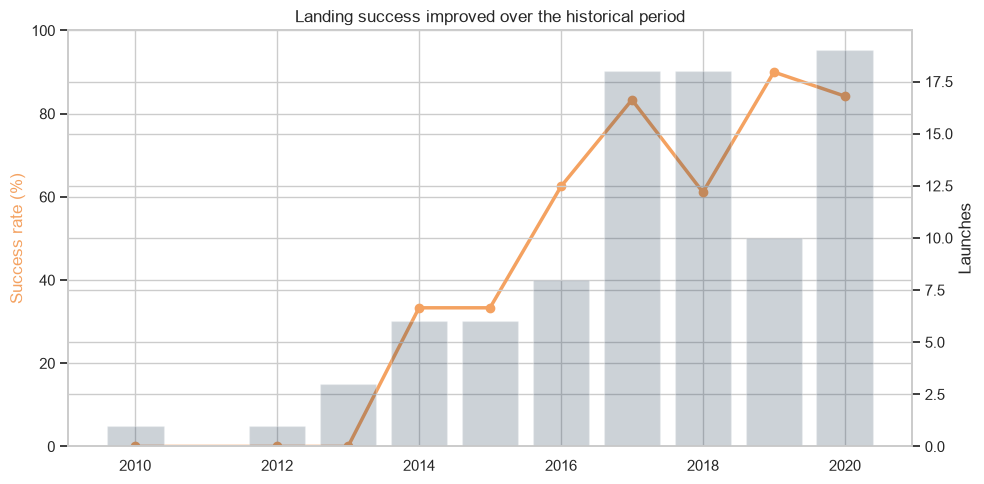

,launches,success_rate
Year,,
2010,1,0.0
2012,1,0.0
2013,3,0.0
2014,6,33.3
2015,6,33.3
2016,8,62.5
2017,18,83.3
2018,18,61.1
2019,10,90.0


In [7]:
yearly = clean.groupby("Year").agg(launches=("Class", "size"), success_rate=("Class", "mean"))
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(yearly.index, yearly["success_rate"] * 100, marker="o", linewidth=2.5, color="#F4A261")
ax1.set_ylabel("Success rate (%)", color="#F4A261")
ax1.set_ylim(0, 100)
ax1.set_title("Landing success improved over the historical period")
ax2 = ax1.twinx()
ax2.bar(yearly.index, yearly["launches"], alpha=0.22, color="#17324D")
ax2.set_ylabel("Launches")
plt.tight_layout()
plt.show()
display(yearly.assign(success_rate=lambda d: (d.success_rate * 100).round(1)))

In [8]:
orbit = clean.groupby("Orbit").agg(launches=("Class", "size"), success_rate=("Class", "mean"))
orbit = orbit.sort_values(["success_rate", "launches"], ascending=False)
display(orbit.assign(success_rate=lambda d: (d.success_rate * 100).round(1)))

,launches,success_rate
Orbit,,
SSO,5,100.0
ES-L1,1,100.0
GEO,1,100.0
HEO,1,100.0
VLEO,14,85.7
LEO,7,71.4
PO,9,66.7
MEO,3,66.7
ISS,21,61.9


## 5. Exploratory data analysis with SQL

The SQL lab uses an in-memory SQLite database to answer operational questions about
launch sites, payload mass, outcomes, dates, and rankings. Representative queries are
executed below rather than copied from a static answer key.

In [9]:
con = sqlite3.connect(":memory:")
sql_data.to_sql("SPACEXTBL", con, index=False, if_exists="replace")

queries = {
    "Distinct launch sites": 'SELECT DISTINCT "Launch_Site" FROM SPACEXTBL ORDER BY 1',
    "NASA CRS payload mass": 'SELECT SUM("PAYLOAD_MASS__KG_") AS total_kg FROM SPACEXTBL WHERE "Customer" LIKE "NASA (CRS)%"',
    "First successful ground-pad landing": '''SELECT MIN("Date") AS first_date FROM SPACEXTBL WHERE "Landing_Outcome" = "Success (ground pad)"''',
    "Launch-site ranking": '''SELECT "Launch_Site", COUNT(*) AS launches FROM SPACEXTBL GROUP BY "Launch_Site" ORDER BY launches DESC''',
}
for label, query in queries.items():
    print(f"\n{label}")
    display(pd.read_sql_query(query, con))


Distinct launch sites


,Launch_Site
0,CCAFS LC-40
1,CCAFS SLC-40
2,KSC LC-39A
3,VAFB SLC-4E



NASA CRS payload mass


,total_kg
0,48213



First successful ground-pad landing


,first_date
0,2015-12-22



Launch-site ranking


,Launch_Site,launches
0,CCAFS SLC-40,34
1,CCAFS LC-40,26
2,KSC LC-39A,25
3,VAFB SLC-4E,16


In [10]:
pd.read_sql_query(
    '''SELECT "Booster_Version", "Payload", "PAYLOAD_MASS__KG_"
       FROM SPACEXTBL
       WHERE "Landing_Outcome" = "Success (drone ship)"
         AND "PAYLOAD_MASS__KG_" BETWEEN 4000 AND 6000
       ORDER BY "PAYLOAD_MASS__KG_"''',
    con,
)

,Booster_Version,Payload,PAYLOAD_MASS__KG_
0,F9 FT B1026,JCSAT-16,4600
1,F9 FT B1022,JCSAT-14,4696
2,F9 FT B1031.2,SES-11 / EchoStar 105,5200
3,F9 FT B1021.2,SES-10,5300


## 6. Interactive visual analytics

The project provides two interactive artifacts:

- **Folium maps** in `figures/`: launch-site markers, clustered landing records, and
  proximity lines to coastline, rail, roadway, and Titusville.
- **Plotly Dash app** in `app/spacex_dash_app.py`: launch-site dropdown, payload-mass
  range slider, success pie chart, and payload-versus-outcome scatter plot.

In [11]:
pd.DataFrame(SUMMARY["proximities"]).style.format({"distance_km": "{:.1f} km"})

,feature,distance_km
0,Atlantic coastline,7.0 km
1,NASA railway,0.9 km
2,NASA Causeway,6.3 km
3,Titusville,16.3 km


In [12]:
display(HTML('<iframe src="../figures/folium_launch_sites.html" width="100%" height="520"></iframe>'))

/Users/nguyentantai/.cache/uv/archive-v0/5Ib2AHIwsxR-xJRR/lib/python3.13/site-packages/IPython/core/display.py:448: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


## 7. Predictive analysis

,model,cv_accuracy,test_accuracy,precision,recall,f1
0,K-nearest neighbors,84.8,83.3,80.0,100.0,88.9
1,Support vector machine,83.4,83.3,80.0,100.0,88.9
2,Logistic regression,82.0,83.3,80.0,100.0,88.9
3,Decision tree,84.7,77.8,78.6,91.7,84.6


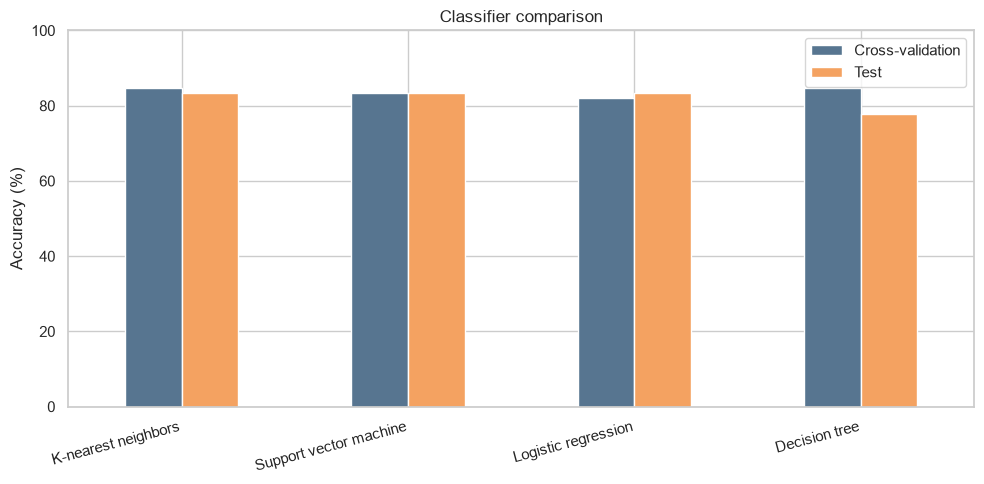

In [13]:
models = pd.DataFrame(SUMMARY["model"]["models"])
metrics = models[["model", "cv_accuracy", "test_accuracy", "precision", "recall", "f1"]].copy()
for column in metrics.columns[1:]:
    metrics[column] = (metrics[column] * 100).round(1)
display(metrics)

ax = metrics.set_index("model")[["cv_accuracy", "test_accuracy"]].plot(
    kind="bar", figsize=(10, 5), color=["#577590", "#F4A261"]
)
ax.set(title="Classifier comparison", ylabel="Accuracy (%)", xlabel="", ylim=(0, 100))
ax.legend(["Cross-validation", "Test"])
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

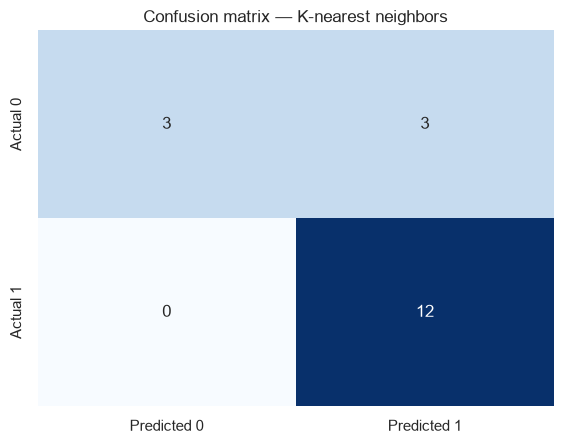

Best model: K-nearest neighbors
Test split: {'train_rows': 72, 'test_rows': 18, 'random_state': 2}


In [14]:
cm = np.array(SUMMARY["model"]["confusion_matrix"])
plt.figure(figsize=(5.8, 4.6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Predicted 0", "Predicted 1"],
            yticklabels=["Actual 0", "Actual 1"])
plt.title(f'Confusion matrix — {SUMMARY["model"]["best_model"]}')
plt.tight_layout()
plt.show()
print("Best model:", SUMMARY["model"]["best_model"])
print("Test split:", SUMMARY["model"]["split"])

## 8. Conclusions and limitations

- The historical landing success rate is **66.7%**, with a clear improvement after
  2015 and rates above 80% in 2017, 2019, and 2020.
- KSC LC‑39A has the highest observed site rate (**77.3%**), narrowly ahead of VAFB
  SLC‑4E (**76.9%**); site, orbit, and mission era are therefore useful signals.
- KNN, SVM, and logistic regression each reach **83.3% test accuracy**. KNN is selected
  by higher cross-validation accuracy, not by a unique test-set win.
- The KNN confusion matrix has 12 true positives, 3 true negatives, 3 false positives,
  and no false negatives. This favors recall but may over-predict successful landings.
- The 18-row test set is too small for a strong production claim. A future study should
  use time-aware validation and newer launch data to test whether the relationships
  remain stable.

## Sources

- IBM Skills Network Applied Data Science Capstone course datasets
- SpaceX v4 API: https://api.spacexdata.com/v4/launches/past
- Wikipedia: List of Falcon 9 and Falcon Heavy launches
- OpenStreetMap contributors for Folium map tiles